**Подготовка конечно-элементной модели поршня**

Этот ноутбук выполняет **подготовительный этап** осесимметричного расчёта стационарной теплопроводности поршня:

1. Загружает размеченную геометрию из Gmsh (`.xao`) и строит двумерную сетку.
2. Извлекает координаты узлов `pnts` и связность треугольников `elms`.
3. Получает граничные рёбра по **именам Physical Groups**.
4. Проверяет разметку на рисунке и сохраняем три файла CSV/JSON.

В основном семинаре будем использовать готовые массивы **без повторного запуска Gmsh**.

В отличие от предыдущей задачи о квадратной пластине, границы поршня здесь не ищем по координатам: их уже разметили в CAD/Gmsh. Геометрия задаёт *где* находится участок теплообмена, а коэффициент теплоотдачи и температуру среды укажем позднее в расчётном ноутбуке.

### 1. Библиотеки и пути к файлам

In [1]:
## для экспорта словаря
import json
## работа с матрицами, математика
import numpy as np
## отображение и графики
import matplotlib.pyplot as plt
## работа с геометрией и сеткой
import gmsh
from pathlib import Path

In [2]:
# Подготовленная геометрия с именованными граничными участками.
# Имя файла можно изменить, если XAO сохранён под другим названием.
geo_file = Path(r"_geom\test_geo.xao")
# STEP нужен только для первоначальной ручной разметки, если XAO ещё нет.
step_file = Path(r"_geom\geom_step.stp")
# Сгенерированная сетка и массивы для основного расчёта.
mesh_path = Path(r"_geom\piston.msh")
export_dir = Path("_mesh")

### 2. Геометрия поршня и генерация сетки

**Геометрическая модель** задаёт меридиональное сечение поршня в плоскости $(r,z)$. При его вращении вокруг оси $z$ получается осесимметричное тело. В файле STEP находится CAD-геометрия, но сама по себе она не содержит назначенных в Gmsh физических групп.

**Physical Groups** — это именованные наборы геометрических объектов. В нашем случае каждой группе соответствует один или несколько участков контура поршня, например `oil_gallery`, `combustion_chamber`, `ring1_top`. Имена позволяют в дальнейшем задавать граничные условия без обращения к числовым номерам CAD-кривых.

Для семинара используется подготовленный файл **`test_geo.xao`**, в котором сохранены геометрия и группы. Если он уже существует, Gmsh откроет его без запуска графического интерфейса. Если файл отсутствует, вы можете импортировать `geom_step.stp`, выделить нужные кривые в интерфейсе Gmsh и сохранить размеченную модель в XAO по указанному пути.

Для ручной разметки в Gmsh нужны команды **Geometry → Physical groups → Add → Curve**: последовательно выбираем кривые одной зоны, нажимаем `e` для завершения выделения, затем создаём следующую группу. Кроме групп кривых необходимо иметь геометрическую поверхность поршня, на которой будет строиться двумерная сетка.

`gmsh.initialize()` начинает работу с Gmsh. После завершения подготовки и извлечения данных вызовем `gmsh.finalize()`.


### Программный комплекс Gmsh

**Gmsh** — свободное программное обеспечение с открытым исходным кодом, предназначенное для генерации конечно-элементных сеток, работы с геометрическими моделями и визуализации результатов численных расчётов.

Программа разработана Кристофом Гезеном (Christophe Geuzaine) и Жаном-Франсуа Ремаклем (Jean-François Remacle) и применяется в научных исследованиях и инженерных задачах, в том числе при использовании метода конечных элементов (МКЭ).

Gmsh поддерживает построение одномерных, двумерных и трёхмерных сеток из различных типов конечных элементов:

- **Линейные элементы** — для дискретизации кривых и границ расчётной области.
- **Треугольные и четырёхугольные элементы** — для двумерных задач.
- **Тетраэдральные, гексаэдральные и другие объёмные элементы** — для трёхмерных задач.

В зависимости от геометрии и выбранного алгоритма Gmsh позволяет создавать два основных типа сеток:

- **Неструктурированные сетки** — элементы располагаются без регулярной схемы нумерации и соседства. Они удобны для дискретизации областей сложной геометрии.
- **Структурированные сетки** — элементы формируются с регулярной организацией узлов и связей между ними. Для их построения Gmsh поддерживает, в частности, трансфинитную интерполяцию (*Transfinite Meshing*) и построение сеток методом выдавливания (*Extrusion*).

Для сложных геометрических областей структурированная сетка обычно требует предварительного разделения геометрии на подходящие блоки. При этом независимо от способа генерации Gmsh предоставляет элементы через их узловую связность.

### Работа с геометрией

Gmsh позволяет не только создавать геометрию собственными средствами, но и импортировать CAD-модели, подготовленные в других программных комплексах, например в Ansys SpaceClaim.

Для обмена геометрическими данными могут использоваться форматы STEP и IGES. Работа с такой геометрией осуществляется с помощью геометрического ядра **OpenCASCADE**.

Важной возможностью Gmsh является создание **физических групп (Physical Groups)** — именованных наборов геометрических объектов, которым впоследствии можно сопоставить свойства материала или граничные условия.

В нашем случае физические группы используются для выделения различных участков поверхности поршня: камеры сгорания, масляной галереи, кольцевых канавок и других областей теплообмена.

### Использование Gmsh в Python

Gmsh может работать как самостоятельное приложение с графическим интерфейсом, так и через программный интерфейс **Python API**.

Это позволяет непосредственно из JupyterLab:

1. Загружать подготовленную геометрическую модель.
2. Изменять параметры и генерировать конечно-элементную сетку.
3. Получать координаты узлов и связность элементов.
4. Обращаться к физическим группам для определения граничных участков.
5. Передавать подготовленные данные в собственную программу численного расчёта.

**В данном семинаре Gmsh используется исключительно для подготовки конечно-элементной модели.** Само решение задачи теплопроводности — формирование элементных матриц, сборка глобальной системы и вычисление температурного поля — выполняется отдельно с помощью Python.

Для поршня будем использовать **неструктурированную сетку из линейных треугольных элементов**, поскольку она позволяет дискретизировать сложное меридиональное сечение, включая кольцевые канавки и масляную галерею.

Таким образом, Gmsh обеспечивает переход от CAD-геометрии к конечно-элементной сетке, а дальнейший расчёт выполняется независимо от генератора сетки.

**Дополнительные материалы:**

- [Официальный сайт Gmsh](https://gmsh.info/)
- [Руководство пользователя Gmsh](https://gmsh.info/doc/texinfo/)
- Geuzaine C., Remacle J.-F. *Gmsh: a three-dimensional finite element mesh generator with built-in pre- and post-processing facilities*. International Journal for Numerical Methods in Engineering, 2009, Vol. 79, No. 11, pp. 1309–1331.



### Примеры применения Gmsh

**1. Генерация сетки для задач аэродинамики**


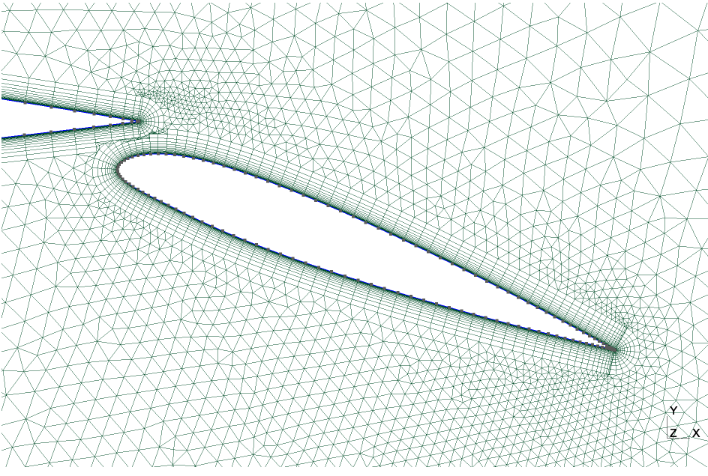

*Рис. 1. Пример сетки вокруг аэродинамического профиля со сгущением элементов вблизи поверхности. Источник: [CfdOF, GitHub](https://github.com/jaheyns/CfdOF/issues/78).*


**2. Конечно-элементная сетка машиностроительной детали**

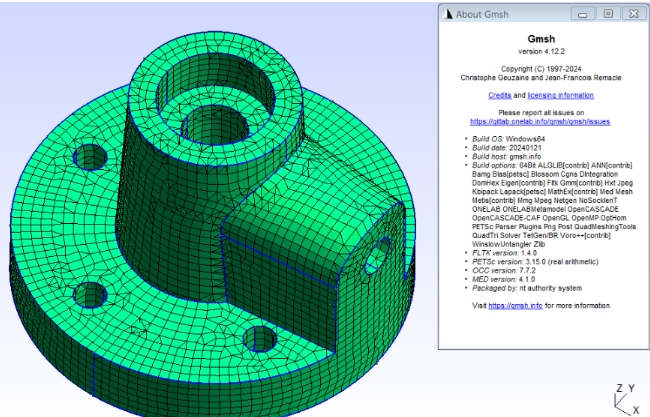

*Рис. 2. Квазиструктурированная четырёхугольная сетка сложной детали. Источник: [PrePoMax Community](https://prepomax.discourse.group/t/gmsh-mesher-quasi-structured-quad-hex-dominant/1219).*

**3. Моделирование композиционных материалов**

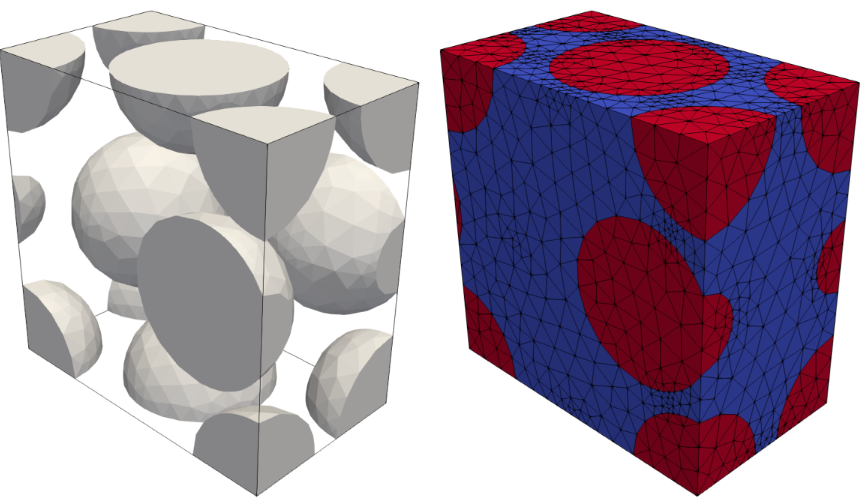

*Рис. 3. Конечно-элементная модель периодической ячейки материала со сферическими включениями. Источник: [GmshModel](https://gmshmodel.readthedocs.io/en/latest/examples/hexagonalCell3DSphere.html).*
0614.html).*


In [3]:
gmsh.initialize()

In [4]:
if not geo_file.exists():
    print("GEO-файл отсутствует. Необходимо подготовить разметку STEP.")
    gmsh.model.add("piston")
    gmsh.option.setString("Geometry.OCCTargetUnit", "M")
    # Загружаем геометрию поршня
    gmsh.model.occ.importShapes(str(step_file))
    gmsh.model.occ.synchronize()
    # Открываем отдельное интерактивное окно Gmsh
    gmsh.fltk.run()
else:
    gmsh.open(str(geo_file))
    print(f"Разметка уже существует")

Разметка уже существует


**Построение и сохранение сетки**

В Gmsh построим **двумерную сетку линейных треугольников** на геометрии меридионального сечения. Параметр `h` задаёт максимальный характерный размер элемента в метрах. Аналогично предыдущему семинару, сетку сохраним в отдельном файле `.msh`.

В модели уже должны существовать **Physical Curves** для граничных участков и **Physical Surface** для области поршня. При `Mesh.SaveAll = 0` в файл MSH записываются элементы физических групп. Поэтому без Physical Surface граничные рёбра могут сохраниться, а треугольники — отсутствовать.

In [5]:
# Создание сетки и сохранение в файл
h = 0.001                                         # Размер сетки, м
gmsh.option.setNumber("Mesh.MeshSizeMax", h)
gmsh.option.setNumber("Mesh.ElementOrder", 1)
# Двумерная сетка для осесимметричной задачи
gmsh.model.mesh.generate(2)
mesh_path.parent.mkdir(parents=True, exist_ok=True)
gmsh.write(str(mesh_path))

**Чтение сетки из сохраненного файла**

Откроем записанный файл `.msh` с диска. Это позволит проверить, что он содержит и треугольные элементы, и названия граничных групп. Перед загрузкой удалим предыдущую модель из текущей сессии, чтобы не смешивать исходную геометрию и сохранённую сетку.

In [6]:
# Читаем уже сгенерированную сетку
gmsh.clear()
gmsh.open(str(mesh_path))

### 3. Координаты узлов и связность конечных элементов

Как и в предыдущем семинаре, подготовим два основных массива:

- `pnts` — координаты всех узлов сетки $(r,z)$ в метрах, размерность `nn × 2`;
- `elms` — индексы трёх узлов каждого треугольного конечного элемента, размерность `ne × 3`.

Функции Gmsh возвращают **теги узлов**. В отличие от индексов массивов NumPy, начинающихся с нуля, теги могут быть непоследовательными и не обязаны совпадать с порядком координат, возвращённых `getNodes()`.

In [7]:
node_tags, pnts, _ = gmsh.model.mesh.getNodes()
pnts = pnts.reshape(-1, 3)                            
# Для 2D задачи оставляем x, y
pnts = pnts[:, :2]

In [8]:
_, _, elms = gmsh.model.mesh.getElements(2)
elms = elms[0].reshape(-1, 3)
elms = elms - 1

In [9]:
# сохраним количество элементов, чтобы потом можно было писать циклы по ним
nn = len(pnts)
ne = len(elms) 

Проверим геометрию, отображая все треугольники. **Расчётные координаты остаются в метрах**.

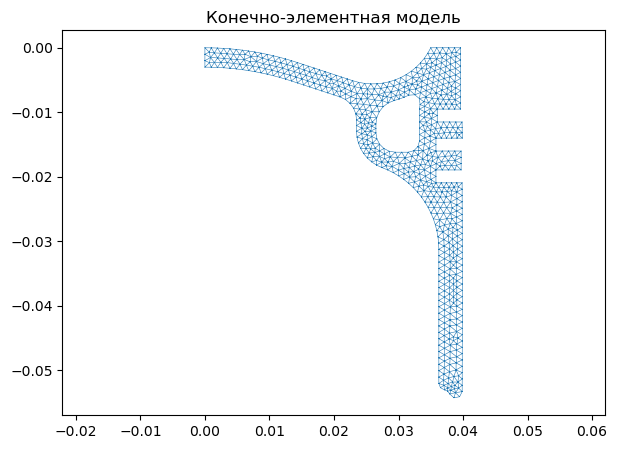

In [10]:
fig, ax = plt.subplots(figsize=(7,5))
plt.title('Конечно-элементная модель')
ax.triplot(pnts[:,0]  , pnts[:,1], elms, linewidth=0.4)
#ax.plot(pnts[:,0], pnts[:,1], 'go', lw=1.0)
#texts = [ax.text(pnts[i,0]+1e-4, pnts[i,1]+1e-4, '%s' %i) for i in range(nn)]
plt.axis('equal')
plt.show()

### 4. Идентификация граничных рёбер по Physical Groups

Для осесимметричного теплообмена недостаточно знать только узлы граничной зоны. Нужно знать **каждое граничное ребро**, его два узла и длину: через эти величины будем вычислять граничные интегралы.

В результате получим словарь `boundary[name]` с полями `nodes`, `elements`, `edges`, `length` — как в предыдущем семинаре.

**Определение граничных элементов и рёбер**

После получения узлов, принадлежащих выбранной физической группе, необходимо определить соответствующие граничные элементы и их рёбра.

Как и в предыдущем семинаре, для этого воспользуемся двумя вспомогательными функциями: `sel_elms()` и `sel_edges()`.

**Функция `sel_elms()`: поиск граничных элементов**

Функция `sel_elms(elms, sel_nds)` определяет треугольные элементы, у которых **ровно два из трёх узлов принадлежат выбранной границе**.

Аргументы функции:

- `elms` — массив связности треугольных элементов, содержащий по три индекса узлов для каждого элемента;
- `sel_nds` — массив индексов узлов выбранной физической группы.

Алгоритм работы:

1. Последовательно перебираем все треугольные элементы сетки.
2. С помощью `np.isin()` проверяем принадлежность каждого из трёх узлов элемента массиву `sel_nds`.
3. Подсчитываем количество совпадений.
4. Если ровно два узла принадлежат выбранной границе, сохраняем индекс элемента.

Условие отбора можно записать в виде:

$$
\boxed{
\sum_{k=1}^{3}
\mathbb{I}(n_{e,k}\in\mathrm{sel\_nds})=2,
}
$$

где $n_{e,k}$ — индекс $k$-го узла элемента $e$, а $\mathbb{I}$ — индикаторная функция, принимающая значение 1 при выполнении условия и 0 в противном случае.

**Результат:** массив `sel_elms`, содержащий индексы отобранных треугольных элементов.

**Функция `sel_edges()`: определение граничных рёбер**

После отбора элементов необходимо определить, какие именно два узла каждого элемента принадлежат выбранной границе.

Для этого используется функция `sel_edges(elms, sel_elms, sel_nds)`.

Аргументы функции:

- `elms` — массив связности треугольных элементов;
- `sel_elms` — индексы элементов, полученные предыдущей функцией;
- `sel_nds` — индексы узлов выбранной границы.

Для каждого отобранного элемента функция с помощью `np.isin()` определяет два узла, принадлежащих `sel_nds`, и сохраняет их индексы как пару:

$$
\Gamma_e=[i,j],
$$

где $i$ и $j$ — индексы узлов предполагаемого граничного ребра.

**Результат:** массив `edges` размером $N_{\Gamma}\times2$, каждая строка которого содержит пару индексов узлов одного ребра.

Полученный массив используется для вычисления длин рёбер:

$$
\boxed{
L_e=\sqrt{(r_j-r_i)^2+(z_j-z_i)^2}
}
$$

и последующего формирования граничных условий теплообмена.

**Важно:** рассмотренный алгоритм предполагает, что у каждого граничного треугольника ровно два узла принадлежат выбранной физической группе. Для сложных сеток это условие не всегда выполняется: элемент может иметь три узла на границе, а два выбранных узла не обязательно образуют ребро нужной CAD-кривой. Поэтому такой способ является упрощённым. При необходимости граничные рёбра можно получать непосредственно из одномерных элементов физических групп Gmsh.


In [11]:
def sel_elms(elms, sel_nds):
    sel_elms = []
    for el in range(ne):
        n = np.isin(elms[el], sel_nds).sum()
        if n == 2:
            sel_elms.append(el)
    return np.array(sel_elms, dtype=int) 

In [12]:
def sel_edges(elms, sel_elms, sel_nds):
    edges = []
    for el in sel_elms:
        edge = elms[el][np.isin(elms[el], sel_nds)]
        edges.append(edge)
    return np.array(edges, dtype=int) 

Переберём физические группы **размерности 1**, соответствующие CAD-кривым. Название группы будет ключом словаря `boundary`, а её элементные данные — значениями.

В словаре `nodes` и `edges` используются **индексы массива `pnts`**, а не исходные теги Gmsh. Поле `length` содержит длины рёбер в метрах. Поле `elements` содержит индексы треугольников, прилегающих к каждому граничному ребру; поэтому его длина совпадает с количеством рёбер.

In [13]:
boundary = {}
for dim, tag in gmsh.model.getPhysicalGroups(1):
    name  = gmsh.model.getPhysicalName(dim, tag)
    nodes, _ = gmsh.model.mesh.getNodesForPhysicalGroup(dim, tag)
    nodes = nodes - 1
    elements = sel_elms(elms, nodes)
    edges = sel_edges(elms, elements, nodes)
    
    L = []
    for nd1, nd2 in edges:
        L.append(np.linalg.norm(pnts[nd2] - pnts[nd1]))
    L = np.array(L)
    boundary[name] = {
            'nodes': nodes,
            'elements': elements,
            'edges': edges,
            'length': L
        }

**Проверка расположения физических групп**

Отобразим найденные граничные рёбра поверх конечно-элементной сетки. Каждому имени Physical Group сопоставим цвет и подпись. Так можно проверить, что участки камеры сгорания, масляной галереи, кольцевых канавок и другие зоны действительно соответствуют нужным частям поршня.


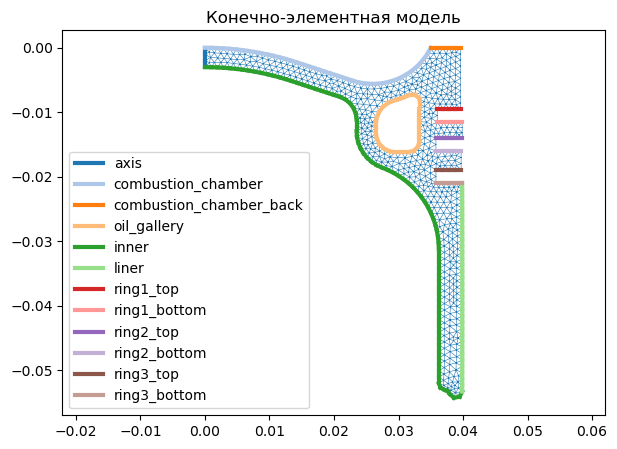

In [14]:
# Отображение всех физических групп
colors = plt.get_cmap("tab20").colors
# картинка
fig, ax = plt.subplots(figsize=(7,5))
plt.title('Конечно-элементная модель')
ax.triplot(pnts[:,0]  , pnts[:,1]  , elms, linewidth=0.4)
for i, bc in enumerate(boundary):
    edges = boundary[bc]['edges']
    plt.plot(pnts[edges, 0].T, pnts[edges, 1].T, color=colors[i], lw=3)
    plt.plot([], [], color=colors[i], lw=3, label=bc)
plt.axis('equal')
plt.legend(loc='lower left')
plt.show()

In [15]:
# Данные уже получены, Gmsh больше не нужен
gmsh.finalize()


## 5. Экспорт данных для расчёта

После извлечения всех необходимых данных Gmsh больше не нужен. Основной расчёт температурного поля поршня будет выполняться с помощью NumPy и SciPy.

Для дальнейшей работы сохраним подготовленные данные в **три отдельных файла в текстовых форматах CSV и JSON**:

- **`nodes.csv`** — координаты узлов конечно-элементной сетки в метрах. Содержит два столбца: `r` и `z`.
- **`elements.csv`** — связность треугольных конечных элементов. Содержит три столбца: `i`, `j`, `m` — индексы узлов каждого элемента.
- **`boundary.json`** — словарь физических групп, содержащий для каждой границы массивы `nodes`, `elements`, `edges` и `length`.

Все индексы узлов начинаются с нуля и соответствуют порядку строк в `nodes.csv`.

Форматы CSV и JSON позволяют **просматривать содержимое файлов непосредственно в JupyterLab или текстовом редакторе**. При этом для сохранения и загрузки данных достаточно стандартных средств Python и библиотеки NumPy.

В основном расчёте данные будут загружаться обратно в массивы `pnts`, `elms` и словарь `boundary`, сохраняя структуру, использованную при подготовке сетки.

Такое разделение позволяет **один раз подготовить конечно-элементную модель**, а затем изменять параметры теплообмена и повторно рассчитывать температурное поле без перестроения сетки.

При изменении геометрии или параметров сетки необходимо заново выполнить подготовительный ноутбук и обновить сохранённые файлы.
овить CSV-файлы.


In [16]:
# Узлы
np.savetxt(export_dir / "nodes.csv", pnts, comments="", delimiter=",", header="r,z",  fmt="%.17g")
# Элементы
np.savetxt(export_dir / "elements.csv", elms, comments="", delimiter=",", header="i,j,m", fmt="%d")
# Граничные условия
with open(export_dir / "boundary.json", "w", encoding="utf-8") as f:
    json.dump(
        {name: {k: v.tolist() for k, v in data.items()}
         for name, data in boundary.items()},
        f, indent=2, ensure_ascii=False
    )

In [17]:
# После загрузки будет работать как раньше !

In [18]:
pnts01 = np.loadtxt(
    export_dir / "nodes.csv",
    delimiter=",", skiprows=1, ndmin=2
)

elms01 = np.loadtxt(
    export_dir / "elements.csv",
    delimiter=",", skiprows=1, dtype=int, ndmin=2
)

with open(export_dir / "boundary.json", encoding="utf-8") as f:
    boundary01 = json.load(f)
